# **CA5** - Predicting Cognitive Health from Lifestyle Habits

# **Group 6** - Narges Zareigolbaghi & Kachina Aschenberg Øwre 
# **Kaggle names** - nargeszareigolbaghi & kachasch

## 1. Imports

We import all the libraries we use, so everything is loaded in one place at the top of the notebook.
- numpy and pandas to work with the data, matplotlib and seaborn for the plots
- scikit-learn tools for preprocessing, pipelines, cross-validation, hyperparameter tuning and the MAE metric
- the models we use: Ridge, RandomForestClassifier and RandomForestRegressor
- `RANDOM_STATE = 42`, used everywhere so the results are the same every time the notebook is run

In [7]:
# Imports for data analysis and visualization
import numpy as np  # numerical computing
import pandas as pd  # dataframes and series
import matplotlib.pyplot as plt  # plotting
import seaborn as sns  # statistical plotting

# Imports for preprocessing, pipelines and model evaluation
from sklearn.pipeline import Pipeline  # chains preprocessing and model
from sklearn.compose import ColumnTransformer  # different preprocessing for numeric and text columns
from sklearn.impute import SimpleImputer  # fills in missing values
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.model_selection import KFold, GridSearchCV, cross_val_predict
from sklearn.metrics import mean_absolute_error  # the Kaggle metric
from sklearn.base import clone  # fresh, untrained copy of a model

# Imports for models
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

# Constants
RANDOM_STATE = 42  # same random state everywhere, so results can be reproduced


## 2. Reading the data

We now have to read the training and test data into pandas DataFrames.
- `id` is used as the index, so it is never used as a feature and the submission gets the right ids
- We check the size of both sets: train has 367,500 rows (15 features and `target`), test has 150,000 rows (15 features)
- The first rows already show missing values (`NaN`) and an impossible value (negative water intake), which we look at in section 3

In [8]:
# Read the data; id becomes the index, so it is never used as a feature
df_train = pd.read_csv("train.csv", index_col="id")
df_test = pd.read_csv("test.csv", index_col="id")

# Size of the data: (rows, columns)
print("Train:", df_train.shape)
print("Test: ", df_test.shape)

# First rows of the training data
df_train.head()


Train: (367500, 16)
Test:  (150000, 15)


,age,sleep_duration_hrs,sleep_quality_score,cardio_mins_wk,water_intake_liters,screen_time_recreational_hrs,social_media_hrs,blood_pressure_sys,diet_ultra_processed_pct,diet_omega3_freq,smoking_status,alcohol_drinks_wk,novel_learning_hrs_wk,social_connection_score,chronic_stress_score,target
id,,,,,,,,,,,,,,,,
193355,55.0,NaN,9.0,20.0,0.900000,3.7,1.1,129.0,47.7,1.0,Never,3.0,1.8,8.0,8.0,27
509850,23.0,6.8,8.0,66.0,-3.634081,NaN,1.8,108.0,29.9,7.0,Never,63.0,0.9,5.0,5.0,28
413954,70.0,9.4,9.0,13.0,2.100000,9.5,5.0,137.0,NaN,2.0,Never,1.0,2.4,8.0,5.0,25
94859,40.0,7.5,10.0,200.0,1.600000,5.0,0.5,124.0,NaN,0.0,Never,7.0,0.9,NaN,8.0,29
18214,18.0,6.9,6.0,81.0,NaN,3.6,1.2,118.0,43.2,2.0,Never,0.0,0.5,5.0,10.0,26


## 3. Data exploration and visualisation before cleaning

This is to find out what is wrong with it and which features are related to the target. Each part ends with a short conclusion.
- 3a: data types, summary statistics and missing values in train and test
- 3b: the distribution of the target, and how many participants have the maximum score of 30
- 3c: histograms of all numeric features, and the smallest and largest values in train and test
- 3d: the number of duplicate rows
- 3e: a correlation heatmap, and the correlation of each feature with the target
- 3f: the target by smoking status

In [9]:
# Section 3a - a look at the data

# 1) Data types and how many values are NOT missing in each column
df_train.info()

# 2) Summary statistics; .T turns the table so each feature is one row
display(df_train.describe().T)

# 3) Missing values per column in train and test, side by side
missing = pd.DataFrame({"train_missing": df_train.isna().sum(),
                        "test_missing": df_test.isna().sum()})
display(missing)

<class 'pandas.DataFrame'>
Index: 367500 entries, 193355 to 186708
Data columns (total 16 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   age                           345653 non-null  float64
 1   sleep_duration_hrs            340323 non-null  float64
 2   sleep_quality_score           357702 non-null  float64
 3   cardio_mins_wk                355386 non-null  float64
 4   water_intake_liters           358969 non-null  float64
 5   screen_time_recreational_hrs  338865 non-null  float64
 6   social_media_hrs              362207 non-null  float64
 7   blood_pressure_sys            357789 non-null  float64
 8   diet_ultra_processed_pct      354171 non-null  float64
 9   diet_omega3_freq              344987 non-null  float64
 10  smoking_status                342146 non-null  str    
 11  alcohol_drinks_wk             346938 non-null  float64
 12  novel_learning_hrs_wk         340773 non-null  float64


,count,mean,std,min,25%,50%,75%,max
age,345653.0,44.734089,17.178694,-129.000000,34.0,44.0,55.0,218.000000
sleep_duration_hrs,340323.0,7.100915,1.291474,-5.934089,6.4,7.1,7.8,20.139134
sleep_quality_score,357702.0,8.258727,1.919521,-11.000000,7.0,8.0,10.0,28.000000
cardio_mins_wk,355386.0,98.868537,138.695219,-1300.000000,24.0,54.0,122.0,1497.000000
water_intake_liters,358969.0,2.201164,0.715956,-5.009674,1.8,2.2,2.6,9.402479
screen_time_recreational_hrs,338865.0,5.509037,2.930716,-24.112509,3.8,5.5,7.2,35.090503
social_media_hrs,362207.0,2.757720,2.174297,-19.159991,1.3,2.4,3.9,24.661864
blood_pressure_sys,357789.0,126.222164,13.173230,-7.000000,119.0,126.0,134.0,259.000000
diet_ultra_processed_pct,354171.0,50.019510,23.564208,-187.354820,36.5,50.0,63.6,287.389128
diet_omega3_freq,344987.0,1.863169,1.878462,-17.000000,1.0,2.0,3.0,21.000000


,train_missing,test_missing
age,21847,0.0
alcohol_drinks_wk,20562,0.0
blood_pressure_sys,9711,0.0
cardio_mins_wk,12114,0.0
chronic_stress_score,17929,0.0
diet_omega3_freq,22513,0.0
diet_ultra_processed_pct,13329,0.0
novel_learning_hrs_wk,26727,0.0
screen_time_recreational_hrs,28635,0.0
sleep_duration_hrs,27177,0.0


**Conclusion 3a:** The training set has 367,500 rows with 15 features and the target; the test set has 150,000 rows.
All features are numeric except `smoking_status`, which is text (Never / Former / Current), and the target is an integer.
Every feature in train has missing values, from about 5,300 (`social_media_hrs`) to 28,600 (`screen_time_recreational_hrs`) per column, while the test set has none.
More than half of the training rows have at least one missing value, so we cannot simply drop them; we fill them in with an imputer inside the pipeline.
`describe()` also shows impossible minimum and maximum values (e.g. age −129 and 218, sleep quality −11 and 28), which we look at in 3c.

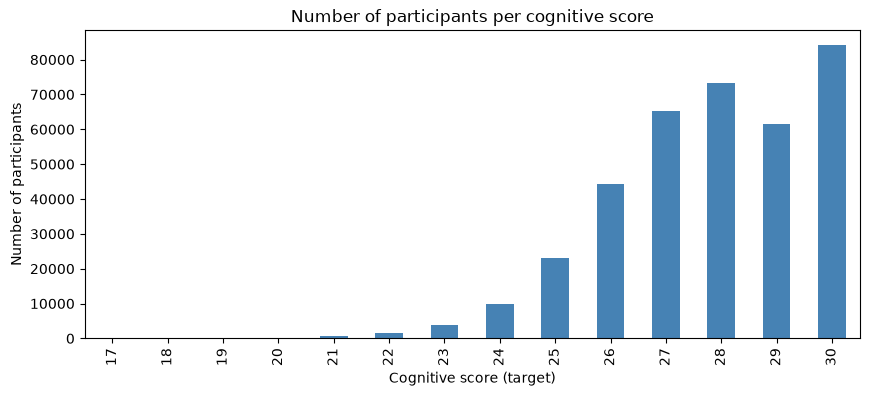

Share with the maximum score 30: 0.229


In [10]:
# Section 3b - The target: how many participants have each score?
counts = df_train["target"].value_counts().sort_index()
counts.plot.bar(figsize=(10, 4), color="steelblue")
plt.title("Number of participants per cognitive score")
plt.xlabel("Cognitive score (target)")
plt.ylabel("Number of participants")
plt.show()

print("Share with the maximum score 30:", round((df_train["target"] == 30).mean(), 3))

**Conclusion 3b:** The scores range from 17 to 30, so no one scores below 17 even though the scale goes down to 5.
Most participants score high (mean 27.8, median 28), and 23% have exactly 30, the ceiling of the scale.
This matters for the models: a regression model can predict values above 30, which are always wrong, and the large group at 30 is the reason for the two-step pipeline C.
As a reference, always predicting 28 gives an MAE of 1.43, so our models must do clearly better than that.

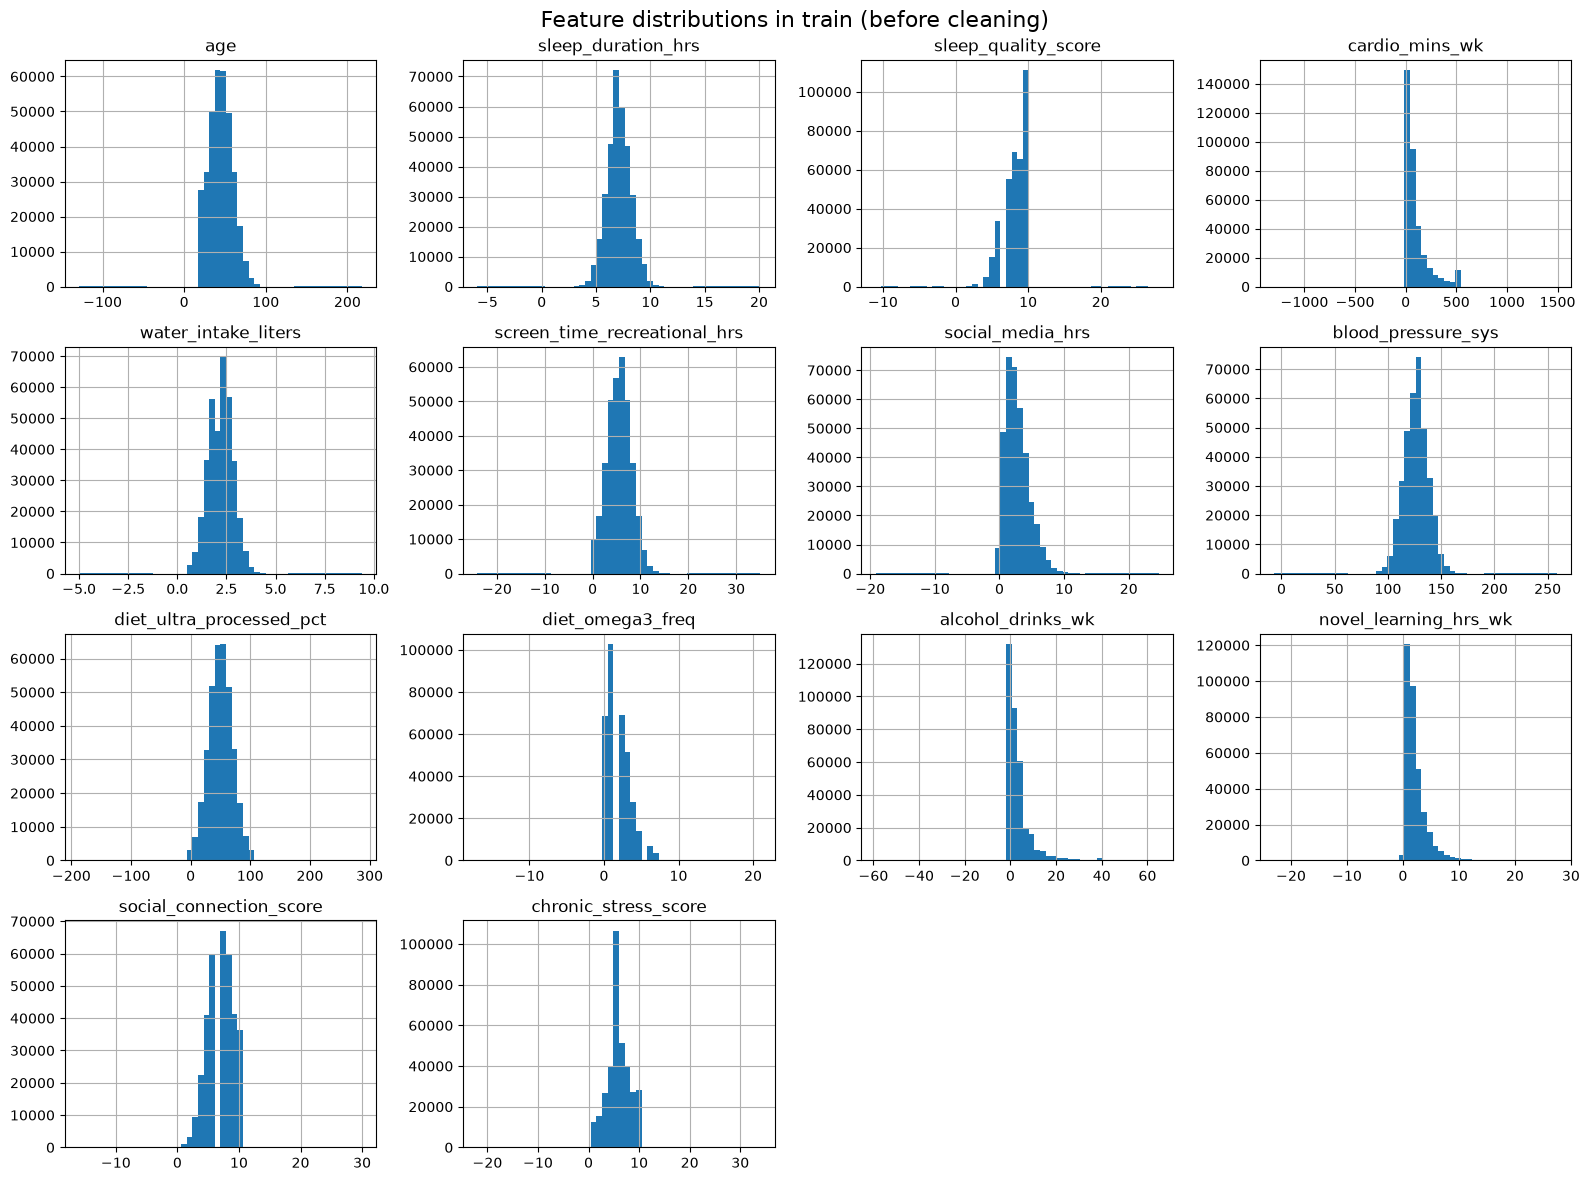

,train_min,test_min,test_max,train_max
age,-129.000000,18.0,90.0,218.000000
sleep_duration_hrs,-5.934089,3.0,12.0,20.139134
sleep_quality_score,-11.000000,1.0,10.0,28.000000
cardio_mins_wk,-1300.000000,0.0,500.0,1497.000000
water_intake_liters,-5.009674,0.5,4.8,9.402479
screen_time_recreational_hrs,-24.112509,0.0,16.0,35.090503
social_media_hrs,-19.159991,0.0,14.1,24.661864
blood_pressure_sys,-7.000000,90.0,174.0,259.000000
diet_ultra_processed_pct,-187.354820,0.0,100.0,287.389128
diet_omega3_freq,-17.000000,0.0,7.0,21.000000


In [11]:
# Section 3c - Distribution of each numeric feature
num_cols = [c for c in df_test.columns if c != "smoking_status"]

df_train[num_cols].hist(bins=50, figsize=(16, 12))
plt.suptitle("Feature distributions in train (before cleaning)", fontsize=16)
plt.tight_layout()
plt.show()

# Smallest and largest values in train and test, side by side
ranges = pd.DataFrame({"train_min": df_train[num_cols].min(),
                       "test_min": df_test[num_cols].min(),
                       "test_max": df_test[num_cols].max(),
                       "train_max": df_train[num_cols].max()})
display(ranges)

**Conclusion 3c:** All 14 numeric features in train contain a small number of impossible values far outside the realistic range, which makes the x-axes of the histograms much wider than the bars (e.g. age from −129 to 218, blood pressure from −7 to 259, negative hours of sleep and screen time).
The test set only contains realistic values (e.g. age 18–90, scores 1–10), so we use the test ranges as limits when cleaning.
Apart from the errors, most features look roughly bell-shaped, while `cardio_mins_wk`, `alcohol_drinks_wk` and `novel_learning_hrs_wk` are right-skewed: most people do a little and a few do a lot.

In [12]:
# Section 3d - Duplicate rows (id is the index, so only the values are compared)
n_duplicates = df_train.duplicated().sum()
print("Duplicate rows in train:", n_duplicates)
print("Share of train:", round(n_duplicates / len(df_train), 3))

Duplicate rows in train: 17500
Share of train: 0.048


**Conclusion 3d:** 17,500 rows (4.8% of train) are exact copies of other rows, leaving 350,000 unique rows.
We remove them, because copies add no new information and give some participants double weight.
They can also make cross-validation too optimistic: if a row is in the training fold and its copy in the validation fold, the model is tested on data it has already seen.

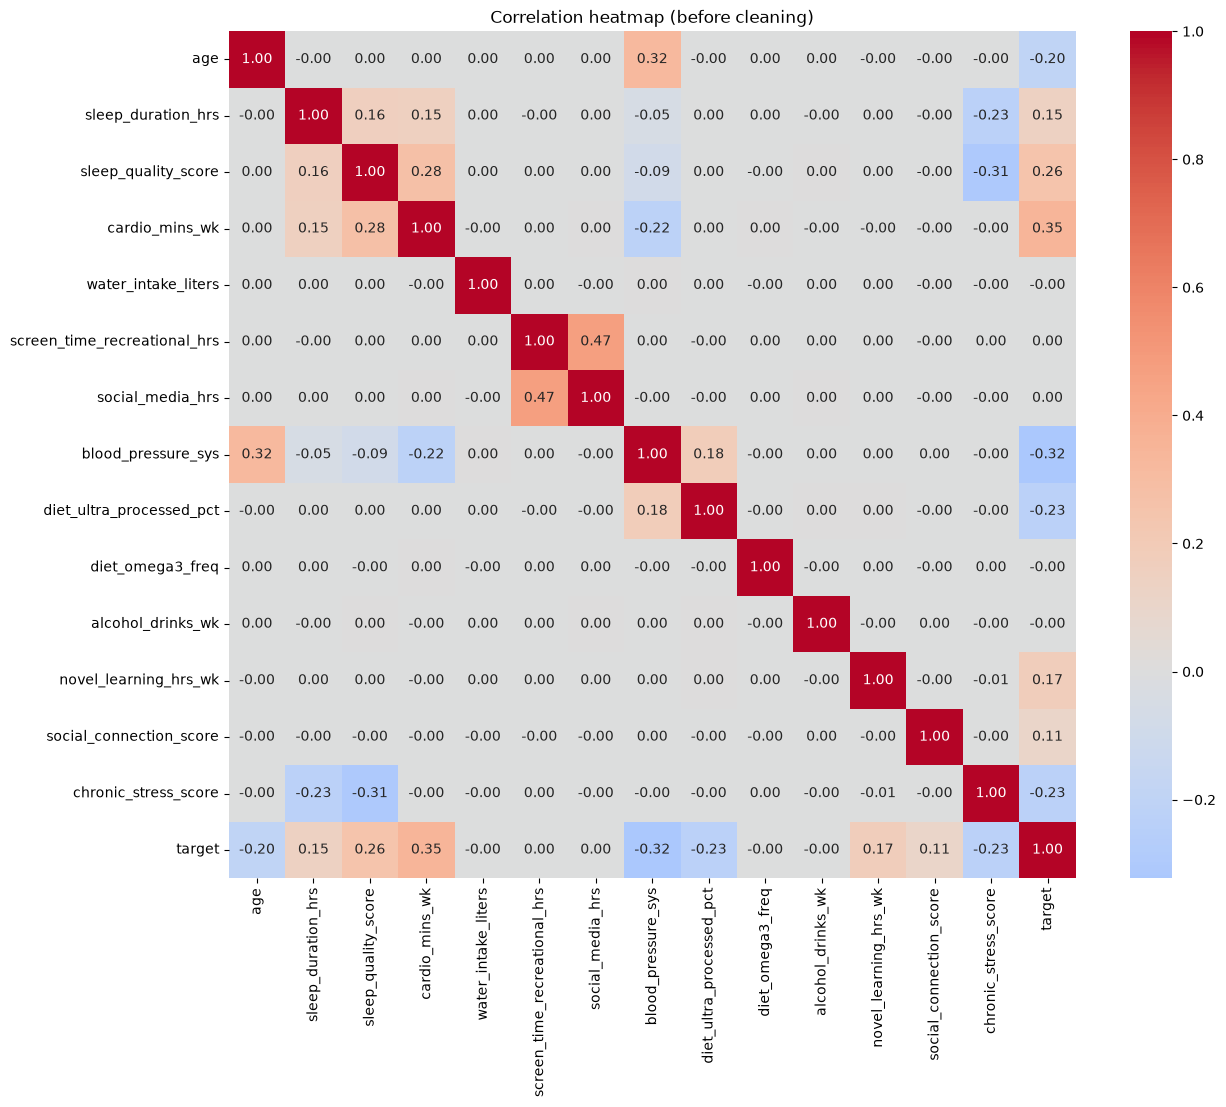

,corr_with_target
blood_pressure_sys,-0.322737
diet_ultra_processed_pct,-0.226910
chronic_stress_score,-0.226133
age,-0.196137
water_intake_liters,-0.001405
diet_omega3_freq,-0.000449
alcohol_drinks_wk,-0.000332
screen_time_recreational_hrs,0.001204
social_media_hrs,0.001909
social_connection_score,0.110867


In [13]:
# Section 3e - Correlation between all numeric columns, including the target
corr = df_train.corr(numeric_only=True)

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True)
plt.title("Correlation heatmap (before cleaning)")
plt.show()

# Correlation of each feature with the target, from most negative to most positive
display(corr["target"].drop("target").sort_values().to_frame("corr_with_target"))

**Conclusion 3e:** The bottom row of the heatmap shows how each feature relates to the target.
Cardio (+0.35), sleep quality (+0.26), novel learning (+0.17), sleep duration (+0.15) and social connection (+0.11) go with a higher score, while blood pressure (−0.32), ultra-processed diet (−0.23), chronic stress (−0.23) and age (−0.20) go with a lower score.
Water intake, omega-3, alcohol, screen time and social media have a correlation of almost exactly 0 with the target, so they may be noise; we test this later.
Most features are not correlated with each other. The exceptions match the data description: screen time and social media (+0.47, social media is part of screen time), age and blood pressure (+0.32), and stress with worse sleep quality (−0.31) and shorter sleep (−0.23).
The impossible values found in 3c weaken all these numbers, so we check the correlations again after cleaning.

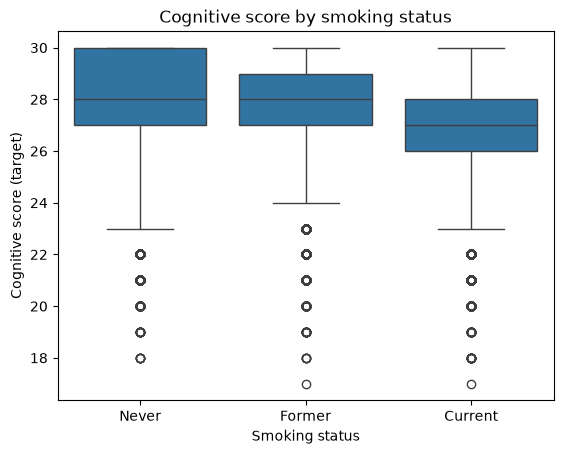

,mean,count
smoking_status,,
Never,28.098045,222643
Former,27.676554,68098
Current,26.781772,51405


In [14]:
# Section 3f - Cognitive score by smoking status
order = ["Never", "Former", "Current"]

sns.boxplot(data=df_train, x="smoking_status", y="target", order=order)
plt.title("Cognitive score by smoking status")
plt.xlabel("Smoking status")
plt.ylabel("Cognitive score (target)")
plt.show()

display(df_train.groupby("smoking_status")["target"].agg(["mean", "count"]).loc[order])

**Conclusion 3f:** Most participants have never smoked (about 65% of those who answered).
The score drops with smoking: the mean is 28.1 for never-smokers, 27.7 for former smokers and 26.8 for current smokers, and the boxes in the boxplot move down in the same order (median 28, 28 and 27).
Never-smokers also reach the maximum score of 30 more often, since their box goes all the way up to 30.
`smoking_status` is therefore a useful feature. It is text, so we one-hot encode it, and its missing values are filled in by an imputer in the pipeline.

## 4. Data cleaning

- Remove the 17,500 exact duplicate rows
- Use the range of the clean test set as the valid range of each feature
- Turn values outside this range into missing values (NaN) instead of dropping the rows, so we keep the good values in those rows
- The missing values are not filled in here; that is done by an imputer inside the pipeline (section 6)

In [15]:
# Section 4 - Data cleaning

# 1) Remove exact duplicate rows
print("Rows before:", len(df_train))
df_train = df_train.drop_duplicates()
print("Rows after removing duplicates:", len(df_train))

# 2) Valid range of each numeric feature = the range in the clean test set
lower = df_test[num_cols].min()
upper = df_test[num_cols].max()

# 3) Find impossible values (True where a value is outside the valid range)
outside = (df_train[num_cols] < lower) | (df_train[num_cols] > upper)

# 4) Turn impossible values into missing values (NaN); the imputer fills them in later
df_train[num_cols] = df_train[num_cols].mask(outside)

# 5) Check the result
summary = pd.DataFrame({"impossible_values": outside.sum(),
                        "missing_after_cleaning": df_train[num_cols].isna().sum()})
display(summary)
print("Rows with at least one impossible value:", outside.any(axis=1).sum())
print("Missing smoking_status:", df_train["smoking_status"].isna().sum())

Rows before: 367500
Rows after removing duplicates: 350000


,impossible_values,missing_after_cleaning
age,1624,22427
sleep_duration_hrs,1619,27511
sleep_quality_score,1702,11017
cardio_mins_wk,1688,13241
water_intake_liters,1699,9799
screen_time_recreational_hrs,1612,28918
social_media_hrs,1686,6733
blood_pressure_sys,1694,10904
diet_ultra_processed_pct,1700,14367
diet_omega3_freq,1640,23097


Rows with at least one impossible value: 22084
Missing smoking_status: 24112


**Conclusion 4:** We removed the 17,500 duplicate rows, which leaves 350,000 rows.
As the valid range of each feature we used the range of the clean test set. Between 1,279 and 1,702 values per feature were outside it, and 22,084 rows (6.3%) had at least one impossible value.
We set these impossible values to missing (NaN) instead of dropping the rows, because the other values in those rows are still good.
All missing values (6,700–28,900 per feature, plus 24,112 in `smoking_status`) are filled in by an imputer inside the pipeline (section 6), so during cross-validation the imputer only learns from the training folds.
The test set is not changed.

## 5. Data exploration and visualisation after cleaning

Now, we check that the cleaning worked, and look at the data again without the impossible values.
- 5a: histograms of all numeric features after cleaning
- 5b: a correlation heatmap after cleaning, and the correlation with the target before and after cleaning

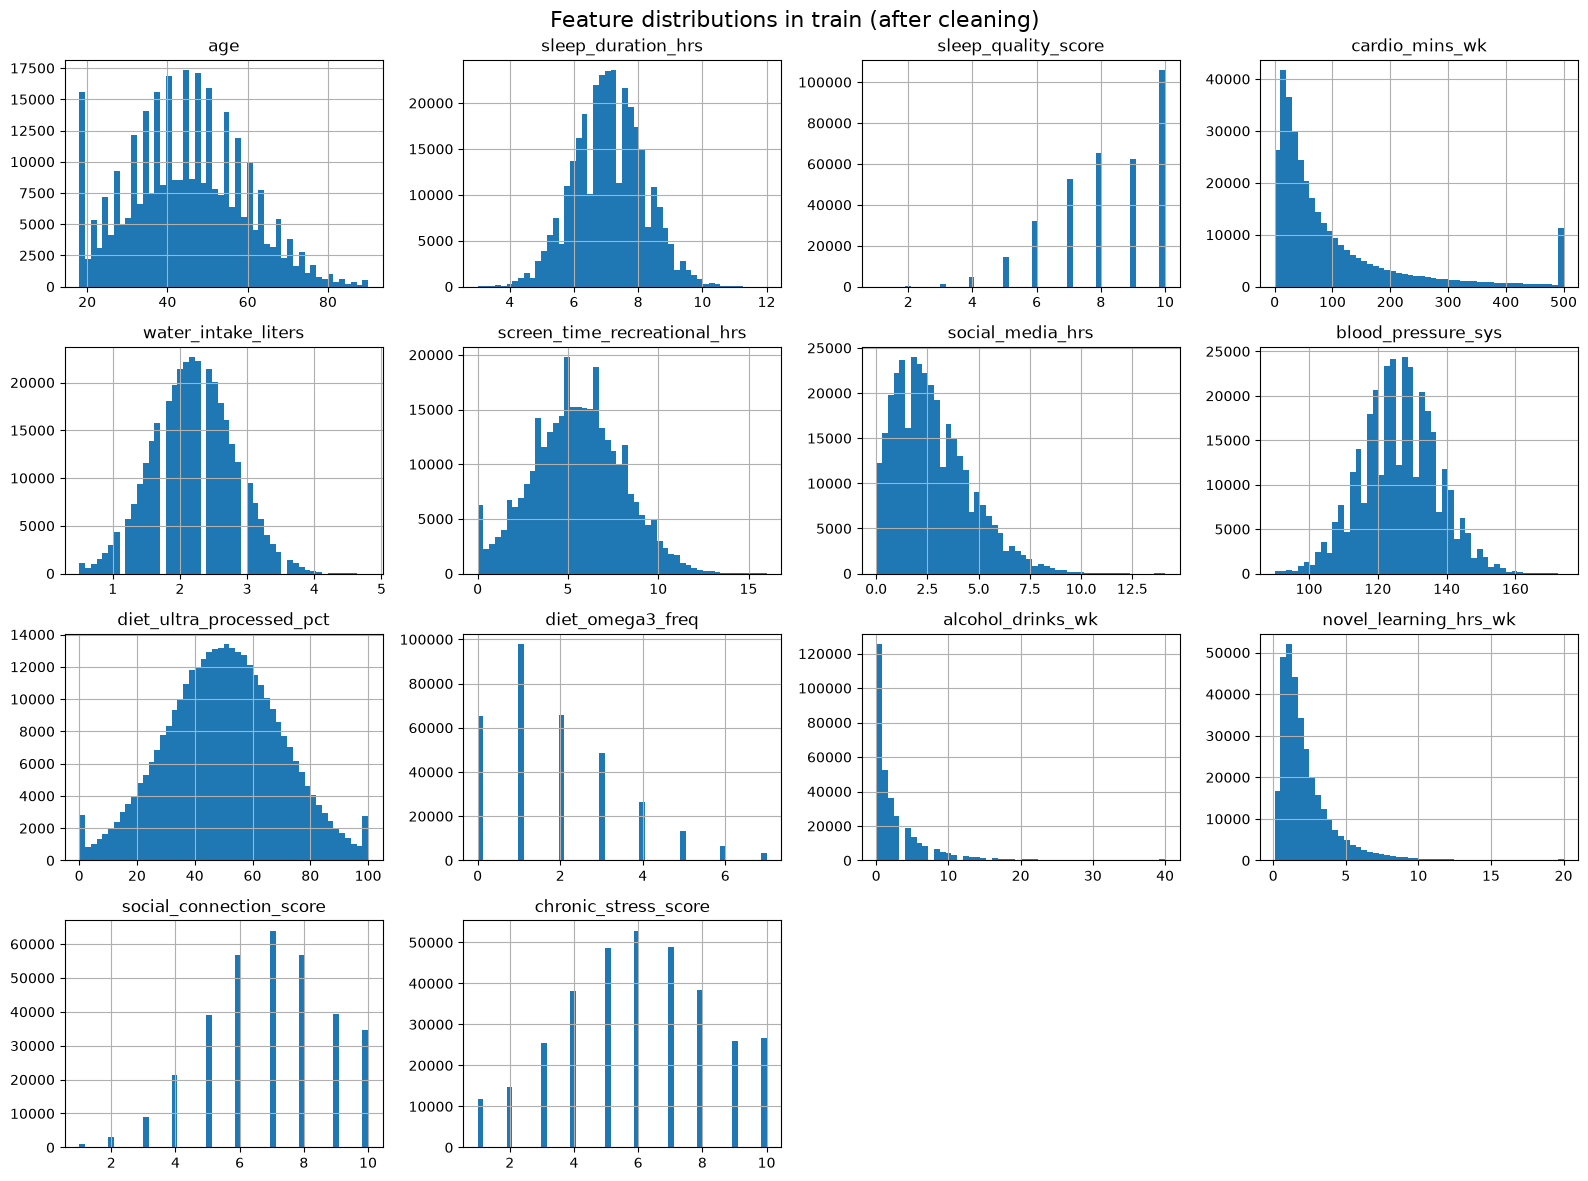

In [16]:
# Section 5a - Histograms after cleaning: all values should now be realistic
df_train[num_cols].hist(bins=50, figsize=(16, 12))
plt.suptitle("Feature distributions in train (after cleaning)", fontsize=16)
plt.tight_layout()
plt.show()

**Conclusion 5a:** After cleaning, all features lie within realistic ranges (e.g. age 18–90, scores 1–10, percentages 0–100).
Now we can see the real shapes: sleep duration, water intake, blood pressure and ultra-processed diet are roughly bell-shaped, while cardio, alcohol, novel learning and social media are right-skewed (most people do a little, a few do a lot).
The small peaks at the limits (age 18, cardio 500, diet 0 and 100) are not errors; the simulation caps the values there.

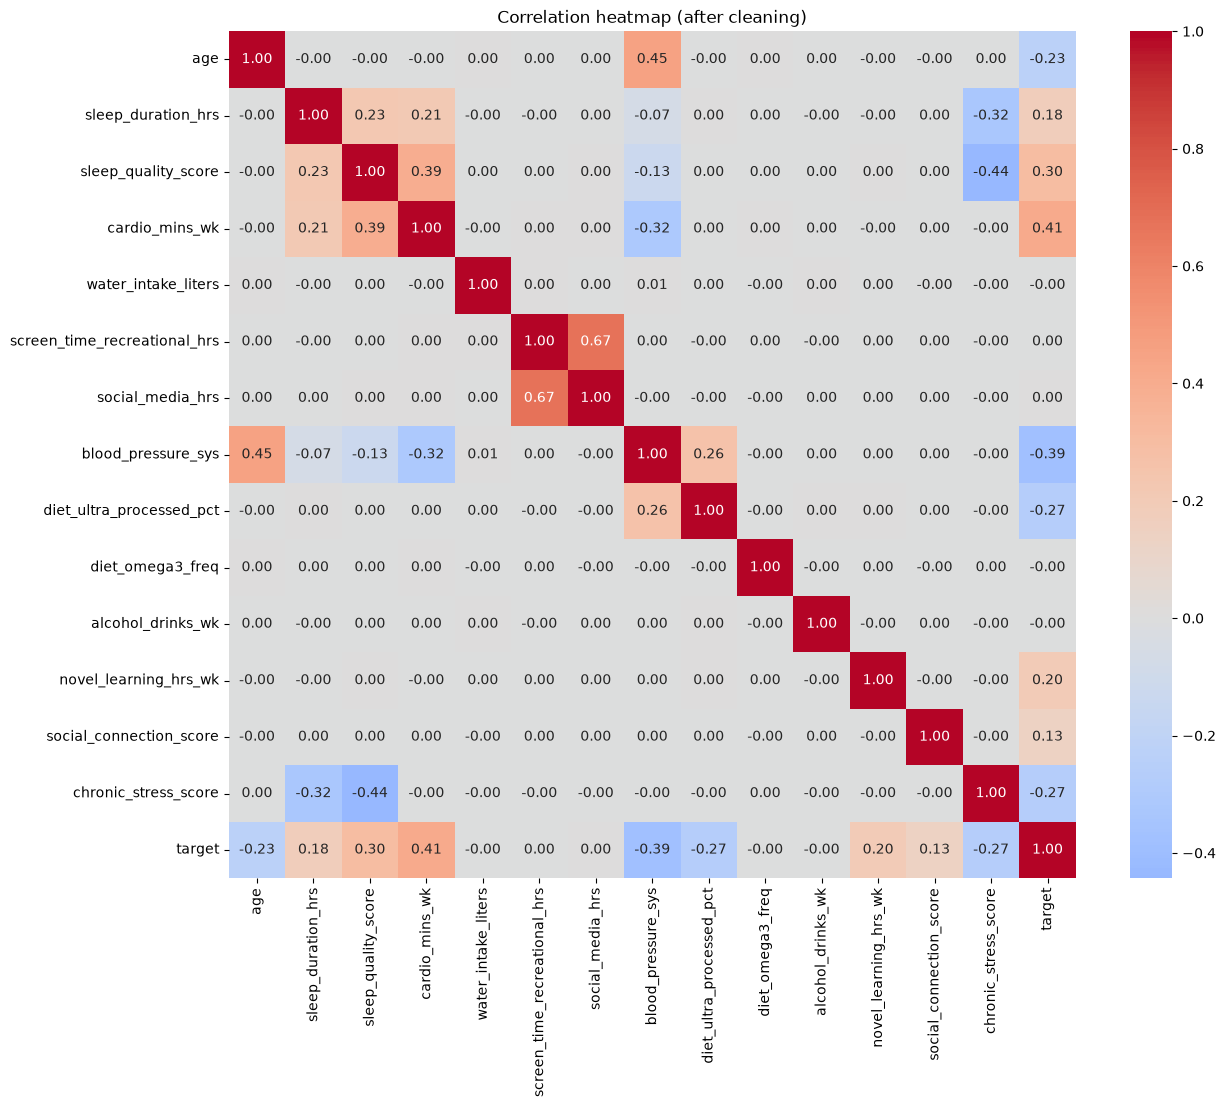

,before_cleaning,after_cleaning
blood_pressure_sys,-0.323,-0.386
diet_ultra_processed_pct,-0.227,-0.272
chronic_stress_score,-0.226,-0.271
age,-0.196,-0.233
water_intake_liters,-0.001,-0.002
diet_omega3_freq,-0.000,-0.001
alcohol_drinks_wk,-0.000,-0.000
screen_time_recreational_hrs,0.001,0.002
social_media_hrs,0.002,0.004
social_connection_score,0.111,0.134


In [17]:
# Section 5b - Correlation heatmap after cleaning
corr_clean = df_train.corr(numeric_only=True)

plt.figure(figsize=(14, 11))
sns.heatmap(corr_clean, cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True)
plt.title("Correlation heatmap (after cleaning)")
plt.show()

# Correlation with the target before and after cleaning
compare = pd.DataFrame({"before_cleaning": corr["target"],
                        "after_cleaning": corr_clean["target"]}).drop("target")
display(compare.sort_values("after_cleaning").round(3))

**Conclusion 5a:** After cleaning, all features lie within realistic ranges (e.g. age 18–90, scores 1–10, percentages 0–100).
Now we can see the real shapes: sleep duration, water intake, blood pressure and ultra-processed diet are roughly bell-shaped, while cardio, alcohol, novel learning and social media are right-skewed (most people do a little, a few do a lot).
The small peaks at the limits (age 18, cardio 500, diet 0 and 100) are not errors; the simulation caps the values there.

## 6. Data preprocessing

Prepare the data for the models. All preprocessing is put inside scikit-learn pipelines, so during cross-validation it only learns from the training folds (no data leakage).
- Split the cleaned training data into the features `X` and the target `y`
- Numeric features: fill in missing values with the median and standardise them (`SimpleImputer` + `StandardScaler`)
- `smoking_status`: fill in missing values with the most common value and one-hot encode it (`SimpleImputer` + `OneHotEncoder`)
- Combine both in one `ColumnTransformer`, and set up 5-fold cross-validation (`KFold`)
- The training set is large, so we tune the models on a random sample of 50,000 rows and train the final model on all rows

## 7. Pipeline A - Regression

Build our first model: a regression pipeline based on linear regression, which predicts the score directly.
- The pipeline is: preprocessing → `PolynomialFeatures` → `Ridge` (linear regression with regularisation)
- `PolynomialFeatures` adds squared and combined features, so the linear model can also follow curved relationships
- We tune the polynomial degree and the regularisation strength `alpha` with `GridSearchCV`, using 5-fold cross-validation and MAE as the score
- We report the best hyperparameters and the cross-validated MAE, and compare it with the baseline of always predicting 28 (MAE 1.43)

## 8. Pipeline B - Classification on the binned target

Turn the regression problem into a classification problem: the score is split into bins, and an ensemble classifier predicts which bin each participant belongs to.
- The target is binned into equally wide bins with `pd.cut`
- The pipeline is: preprocessing → `RandomForestClassifier`, tuned with `GridSearchCV`
- Each predicted bin is turned back into a score (the median score of that bin in the training data), so we can compute the MAE
- We test 3, 5, 10 and 14 bins with 5-fold cross-validation and comment on how the number of bins affects the MAE

## 9. Pipeline C - Two-step model

Build a two-step model that uses the fact that 23% of the participants have the maximum score of 30.
- Step 1: a `RandomForestClassifier` predicts whether a participant scores 30 or below 30
- Step 2: a regression model, trained only on participants below 30, predicts the score of everyone the classifier puts below 30
- Both steps are tuned with `GridSearchCV`, and their results are combined into one prediction vector: 30 if the classifier says so, otherwise the regression value
- Because these are two pipelines, we evaluate the combined prediction with our own 5-fold cross-validation loop and compute the MAE

## 10. Model comparison and best model

Compare pipelines and choose the best one.
- A table with the cross-validated MAE of each pipeline
- We test two small changes to the predictions: cutting off values above 30 (`np.clip`), since no one can score more than 30, and rounding to whole numbers (`np.round`), since the true scores are integers. We keep a change only if it lowers the MAE.
- We name the best model and explain why it is the best

## 11. Kaggle submission

We have to use the best model to predict the cognitive score of the 150,000 participants in the test set.
- The best model is trained again on all 350,000 cleaned training rows, not only the 50,000-row sample
- We predict the test set and apply the changes that helped in section 10
- The predictions are saved as `submission.csv` with the columns `id` and `target`
- We upload the file to Kaggle and report the public leaderboard score, which has to beat the BEAT ME benchmark

## 12. Bonus - Fewest features

We have to find out how many of the original features the research group really needs to measure, since measuring them is expensive.
- We rank the original features by how strongly they are related to the target (section 5)
- We add the features one at a time, from the strongest to the weakest, and compute the cross-validated MAE each time
- We find the smallest set of features whose MAE is at most 10% higher than the MAE of our best model, and list these features